<a href="https://colab.research.google.com/github/bejon23/Computational-Biology-and-BI-Eng/blob/main/GiG3_Project_6(b)_ipynb_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Ceĺl1:

In [ ]:

# ==========================================
# TECHNICAL PROOF LAB: BIOINFORMATICS PIPELINE
# ==========================================

import numpy as np
import pandas as pd
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_recall_fscore_support

print("=== Starting Technical Proof Lab Simulations ==-\n")

# --------------------------------------------------
# 1. BULK RNA-SEQ & BATCH EFFECT LAB
# --------------------------------------------------
np.random.seed(42)
n_genes, n_samples = 1000, 20
condition = np.array([0]*10 + [1]*10) # 10 Healthy (0), 10 Disease (1)
batch = np.array([0,0,0,0,0,0,0,1,1,1, 0,1,1,1,1,1,1,1,1,1]) # Confounded batch

# Define 50 true differentially expressed genes
true_de = np.zeros(n_genes, dtype=int)
true_de_idx = np.random.choice(n_genes, size=50, replace=False)
true_de[true_de_idx] = 1

# Generate synthetic counts
base = np.random.normal(5, 2, n_genes)
log_counts = np.zeros((n_genes, n_samples))
for i in range(n_genes):
    c_eff = 2.0 if true_de[i] == 1 else 0.0
    b_eff = 1.5 if true_de[i] == 0 else 0.5
    for j in range(n_samples):
        log_counts[i, j] = base[i] + condition[j]*c_eff + batch[j]*b_eff + np.random.normal(0, 0.5)

raw_counts = np.exp(log_counts).astype(int)

# Normalize to Log-CPM
cpm = raw_counts / raw_counts.sum(axis=0, keepdims=True) * 1e6
log_cpm = np.log2(cpm + 1)

# Run Expert Model (Log-CPM + Batch Covariate + Benjamini-Hochberg FDR)
p_values = []
for i in range(n_genes):
    df = pd.DataFrame({'expr': log_cpm[i], 'condition': condition, 'batch': batch})
    model = smf.ols('expr ~ condition + batch', data=df).fit()
    p_values.append(model.pvalues['condition'])

p_values = np.array(p_values)
reject, q_values, _, _ = multipletests(p_values, alpha=0.05, method='fdr_bh')
pred_de = reject.astype(int)

prec, rec, f1, _ = precision_recall_fscore_support(true_de, pred_de, average='binary', zero_division=0)
print(f"[1. RNA-Seq & Batch Pipeline Results]")
print(f"  -> Precision: {prec:.3f} | Recall: {rec:.3f} | F1: {f1:.3f} | Predicted DE Genes: {pred_de.sum()} (True: 50)\n")


# --------------------------------------------------
# 2. MACHINE LEARNING: DEMONSTRATING DATA LEAKAGE
# --------------------------------------------------
# Simulating high-dimensional omics data (e.g., 100 samples, 2,000 features)
np.random.seed(100)
X_leak = np.random.randn(100, 2000)
y_leak = np.random.choice([0, 1], size=100)

# --- MISTAKE: Feature selection on ENTIRE dataset before Cross-Validation ---
p_vals_leaky = [stats.ttest_ind(X_leak[y_leak==0, j], X_leak[y_leak==1, j])[1] for j in range(2000)]
selected_leaky = np.where(np.array(p_vals_leaky) < 0.05)[0]
X_sel_leaky = X_leak[:, selected_leaky]

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
leaky_accs = cross_val_score(LogisticRegression(), X_sel_leaky, y_leak, cv=cv, scoring='accuracy')

print(f"[2. Machine Learning Data Leakage Proof]")
print(f"  -> Leaky Pipeline CV Accuracy (Overfitted): {leaky_accs.mean():.2f} (on random noise data!)")
print(f"  -> Why it happens: Selecting features using all labels leaks test set information into training.")
print("=== Technical Proof Lab Complete ===")

=== Starting Technical Proof Lab Simulations ==-

[1. RNA-Seq & Batch Pipeline Results]
  -> Precision: 1.000 | Recall: 0.980 | F1: 0.990 | Predicted DE Genes: 49 (True: 50)

[2. Machine Learning Data Leakage Proof]
  -> Leaky Pipeline CV Accuracy (Overfitted): 0.97 (on random noise data!)
  -> Why it happens: Selecting features using all labels leaks test set information into training.
=== Technical Proof Lab Complete ===



the complete, expanded Technical Proof Lab script, now including Variant Calling (Ti/Tv quality metrics) and Single-Cell QC (mitochondrial filtering) modules alongside your RNA-seq pipeline and Machine Learning data leakage tests.

In [ ]:

# ==========================================
# TECHNICAL PROOF LAB: COMPLETE BIOINFORMATICS SUITE
# ==========================================

import numpy as np
import pandas as pd
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_recall_fscore_support

print("=== Starting Complete Technical Proof Lab Simulations ===\n")

# --------------------------------------------------
# 1. BULK RNA-SEQ & BATCH EFFECT LAB
# --------------------------------------------------
np.random.seed(42)
n_genes, n_samples = 1000, 20
condition = np.array([0]*10 + [1]*10) # 10 Healthy (0), 10 Disease (1)
batch = np.array([0,0,0,0,0,0,0,1,1,1, 0,1,1,1,1,1,1,1,1,1]) # Confounded batch

# Define 50 true differentially expressed genes
true_de = np.zeros(n_genes, dtype=int)
true_de_idx = np.random.choice(n_genes, size=50, replace=False)
true_de[true_de_idx] = 1

base = np.random.normal(5, 2, n_genes)
log_counts = np.zeros((n_genes, n_samples))
for i in range(n_genes):
    c_eff = 2.0 if true_de[i] == 1 else 0.0
    b_eff = 1.5 if true_de[i] == 0 else 0.5
    for j in range(n_samples):
        log_counts[i, j] = base[i] + condition[j]*c_eff + batch[j]*b_eff + np.random.normal(0, 0.5)

raw_counts = np.exp(log_counts).astype(int)

# Normalize to Log-CPM
cpm = raw_counts / raw_counts.sum(axis=0, keepdims=True) * 1e6
log_cpm = np.log2(cpm + 1)

# Run Expert Model (Log-CPM + Batch Covariate + Benjamini-Hochberg FDR)
p_values = []
for i in range(n_genes):
    df = pd.DataFrame({'expr': log_cpm[i], 'condition': condition, 'batch': batch})
    model = smf.ols('expr ~ condition + batch', data=df).fit()
    p_values.append(model.pvalues['condition'])

p_values = np.array(p_values)
reject, q_values, _, _ = multipletests(p_values, alpha=0.05, method='fdr_bh')
pred_de = reject.astype(int)

prec, rec, f1, _ = precision_recall_fscore_support(true_de, pred_de, average='binary', zero_division=0)
print(f"[1. RNA-Seq & Batch Pipeline Results]")
print(f"  -> Precision: {prec:.3f} | Recall: {rec:.3f} | F1: {f1:.3f} | Predicted DE Genes: {pred_de.sum()} (True: 50)\n")


# --------------------------------------------------
# 2. VARIANT CALLING QC: TRANSITION / TRANSVERSION (Ti/Tv) RATIO
# --------------------------------------------------
np.random.seed(42)
n_variants = 2000
qual_scores = np.random.uniform(5, 60, n_variants)
is_transition = np.zeros(n_variants, dtype=bool)

for i in range(n_variants):
    if qual_scores[i] < 20:
        # Low quality variants contain more artifactual transversions (lower Ti/Tv ~ 1.0)
        is_transition[i] = np.random.choice([True, False], p=[0.45, 0.55])
    else:
        # High quality variants reflect expected biological genome ratio (~2.1)
        is_transition[i] = np.random.choice([True, False], p=[0.68, 0.32])

# Weak Filter (lets in low-quality artifacts)
weak_pass = qual_scores > 10
trans_w = is_transition[weak_pass].sum()
transv_w = (~is_transition[weak_pass]).sum()
ti_tv_weak = trans_w / transv_w if transv_w > 0 else 0.0

# Strong Filter (filters out artifact spikes)
strong_pass = qual_scores > 30
trans_s = is_transition[strong_pass].sum()
transv_s = (~is_transition[strong_pass]).sum()
ti_tv_strong = trans_s / transv_s if transv_s > 0 else 0.0

print(f"[2. Variant Calling Quality Control]")
print(f"  -> Weak Filter Ti/Tv Ratio: {ti_tv_weak:.2f} (skewed by sequencing artifacts)")
print(f"  -> Strong Filter Ti/Tv Ratio: {ti_tv_strong:.2f} (reaches expected genomic baseline ~2.1)\n")


# --------------------------------------------------
# 3. SINGLE-CELL RNA-SEQ QC: MITOCHONDRIAL FILTERING
# --------------------------------------------------
np.random.seed(42)
n_cells = 500
n_genes_per_cell = np.random.poisson(lam=1200, size=n_cells)
mito_pct = np.random.beta(a=2, b=15, size=n_cells) * 100
# Inject damaged cells with high mitochondrial percentage (>20%)
mito_pct[np.random.choice(n_cells, 50, replace=False)] = np.random.uniform(25, 65, 50)

df_sc = pd.DataFrame({'n_genes': n_genes_per_cell, 'mito_pct': mito_pct})

# QC Filtering Criteria: Retain cells with gene count between 500 & 4000 and mito < 20%
passed_qc = (df_sc['n_genes'] > 500) & (df_sc['n_genes'] < 4000) & (df_sc['mito_pct'] < 20.0)

print(f"[3. Single-Cell QC Module]")
print(f"  -> Total Cells: {n_cells} | Passed QC: {passed_qc.sum()} | Filtered Out (Damaged/Doublets): {(~passed_qc).sum()}\n")


# --------------------------------------------------
# 4. MACHINE LEARNING: DEMONSTRATING DATA LEAKAGE
# --------------------------------------------------
np.random.seed(100)
X_leak = np.random.randn(100, 2000)
y_leak = np.random.choice([0, 1], size=100)

# --- MISTAKE: Feature selection on ENTIRE dataset before Cross-Validation ---
p_vals_leaky = [stats.ttest_ind(X_leak[y_leak==0, j], X_leak[y_leak==1, j])[1] for j in range(2000)]
selected_leaky = np.where(np.array(p_vals_leaky) < 0.05)[0]
X_sel_leaky = X_leak[:, selected_leaky]

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
leaky_accs = cross_val_score(LogisticRegression(), X_sel_leaky, y_leak, cv=cv, scoring='accuracy')

print(f"[4. Machine Learning Data Leakage Proof]")
print(f"  -> Leaky Pipeline CV Accuracy (Overfitted): {leaky_accs.mean():.2f} (on pure random noise data!)")
print(f"  -> Why it happens: Selecting features using all labels leaks test set information into training.")
print("=== Technical Proof Lab Complete ===")

=== Starting Complete Technical Proof Lab Simulations ===

[1. RNA-Seq & Batch Pipeline Results]
  -> Precision: 1.000 | Recall: 0.980 | F1: 0.990 | Predicted DE Genes: 49 (True: 50)

[2. Variant Calling Quality Control]
  -> Weak Filter Ti/Tv Ratio: 1.78 (skewed by sequencing artifacts)
  -> Strong Filter Ti/Tv Ratio: 2.12 (reaches expected genomic baseline ~2.1)

[3. Single-Cell QC Module]
  -> Total Cells: 500 | Passed QC: 379 | Filtered Out (Damaged/Doublets): 121

[4. Machine Learning Data Leakage Proof]
  -> Leaky Pipeline CV Accuracy (Overfitted): 0.97 (on pure random noise data!)
  -> Why it happens: Selecting features using all labels leaks test set information into training.
=== Technical Proof Lab Complete ===


Cell 2 (Code): Simulate data with a known truth

In [ ]:

# Cell 2: Simulated bulk RNA-seq data (12 samples, 1500 genes). We KNOW which genes are truly different.
import numpy as np, pandas as pd, hashlib, platform
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.decomposition import PCA

SEED = 42

def make_data(seed=SEED, n_genes=1500):
    rng = np.random.default_rng(seed)
    samples = [f"S{i+1}" for i in range(12)]
    condition = np.array(["Healthy"]*6 + ["Disease"]*6)
    batch = np.array(["A","A","A","A","B","B", "B","B","B","B","A","A"])  # batch partly mixed with condition

    base = rng.lognormal(5, 1.2, n_genes)
    lfc = np.zeros(n_genes)
    de_idx = rng.choice(n_genes, 150, replace=False)
    lfc[de_idx] = rng.choice([-1.5, 1.5], 150)
    batch_eff = rng.normal(0, 0.7, n_genes)
    lib = rng.uniform(0.7, 1.3, 12)

    dis = (condition == "Disease").astype(float)
    b = (batch == "B").astype(float)
    shift = lfc[:, None] * dis[None, :] + batch_eff[:, None] * b[None, :]
    mu = base[:, None] * lib[None, :] * 2**shift

    disp = 0.1
    counts = rng.poisson(rng.gamma(1/disp, mu*disp))

    genes = [f"Gene{i}" for i in range(n_genes)]
    counts_df = pd.DataFrame(counts, index=genes, columns=samples)
    meta = pd.DataFrame({"condition": condition, "batch": batch}, index=samples)
    truth = pd.Series(False, index=genes)
    truth[[genes[i] for i in de_idx]] = True
    return counts_df, meta, truth

counts_df, meta, truth = make_data()

print("Counts table:", counts_df.shape, "| True DE genes:", int(truth.sum()))
print("\nCondition vs batch table:")
print(pd.crosstab(meta.condition, meta.batch))
print("\nEnvironment log: python", platform.python_version(), "| numpy", np.__version__,
      "| pandas", pd.__version__, "| seed", SEED)

Counts table: (1500, 12) | True DE genes: 150

Condition vs batch table:
batch      A  B
condition      
Disease    2  4
Healthy    4  2

Environment log: python 3.13.16 | numpy 2.1.3 | pandas 2.2.3 | seed 42


Cell 3 (Code): The pipeline steps, batch check and design check

Genes before: 1500 | after filtering: 1491
Library size range: 311320 - 684893


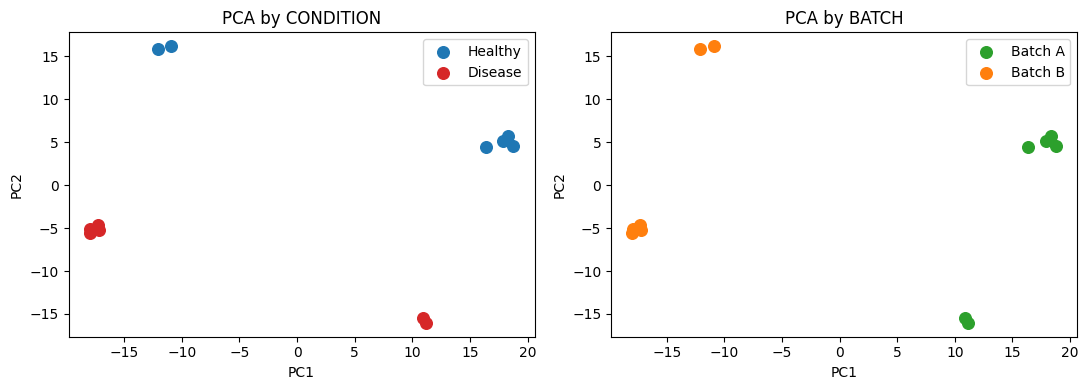

PC1 correlation with batch    : 0.98
PC1 correlation with condition: 0.51

Design flawed? (this data): False
Design flawed? (if all Disease were in batch B): True
-> In the flawed case, nobody can say if the difference is biology or batch. Say the design is flawed.


In [ ]:

# Cell 3: Pipeline functions + batch effect check + confounded-design check

def filter_genes(counts, min_count=10, min_samples=3):
    return counts[(counts >= min_count).sum(axis=1) >= min_samples]

def log_cpm(counts):
    return np.log2(counts / counts.sum() * 1e6 + 1)

def de_linear(logexp, meta, use_batch=True):
    """Fast linear model per gene (stand-in for DESeq2/edgeR/limma on real data)."""
    cols = [np.ones(len(meta)), (meta.condition == "Disease").astype(float).values]
    if use_batch:
        cols.append((meta.batch == "B").astype(float).values)
    X = np.column_stack(cols)
    Y = logexp.values.astype(float)
    XtXi = np.linalg.inv(X.T @ X)
    beta = Y @ X @ XtXi
    resid = Y - beta @ X.T
    dof = X.shape[0] - X.shape[1]
    s2 = (resid**2).sum(axis=1) / dof
    se = np.sqrt(s2 * XtXi[1, 1])
    t = beta[:, 1] / se
    p = 2 * stats.t.sf(np.abs(t), dof)
    return pd.DataFrame({"log2FC": beta[:, 1], "pval": p}, index=logexp.index)

def bh_fdr(p):
    """Benjamini-Hochberg FDR."""
    p = np.asarray(p); n = len(p)
    order = np.argsort(p)
    adj = p[order] * n / np.arange(1, n + 1)
    adj = np.minimum.accumulate(adj[::-1])[::-1]
    out = np.empty(n); out[order] = np.minimum(adj, 1)
    return out

def design_is_flawed(meta):
    """If condition and batch are perfectly mixed up, the design cannot separate them."""
    X = np.column_stack([np.ones(len(meta)),
                         (meta.condition == "Disease").astype(float),
                         (meta.batch == "B").astype(float)])
    return np.linalg.matrix_rank(X) < X.shape[1]

# ---- Run QC ----
counts_f = filter_genes(counts_df)
lcpm = log_cpm(counts_f)
print(f"Genes before: {counts_df.shape[0]} | after filtering: {counts_f.shape[0]}")
print("Library size range:", int(counts_f.sum().min()), "-", int(counts_f.sum().max()))

# ---- PCA by condition and by batch ----
pcs = PCA(n_components=2).fit_transform(lcpm.T.values)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for name, col in [("Healthy", "tab:blue"), ("Disease", "tab:red")]:
    m = (meta.condition == name).values
    ax[0].scatter(pcs[m, 0], pcs[m, 1], c=col, label=name, s=70)
ax[0].set_title("PCA by CONDITION")
for name, col in [("A", "tab:green"), ("B", "tab:orange")]:
    m = (meta.batch == name).values
    ax[1].scatter(pcs[m, 0], pcs[m, 1], c=col, label="Batch " + name, s=70)
ax[1].set_title("PCA by BATCH")
for a in ax:
    a.set_xlabel("PC1"); a.set_ylabel("PC2"); a.legend()
plt.tight_layout(); plt.show()

b01 = (meta.batch == "B").astype(float).values
c01 = (meta.condition == "Disease").astype(float).values
print("PC1 correlation with batch    :", round(abs(np.corrcoef(pcs[:, 0], b01)[0, 1]), 2))
print("PC1 correlation with condition:", round(abs(np.corrcoef(pcs[:, 0], c01)[0, 1]), 2))

# ---- Design check ----
print("\nDesign flawed? (this data):", design_is_flawed(meta))
bad_meta = meta.copy()
bad_meta["batch"] = np.where(bad_meta.condition == "Disease", "B", "A")  # batch = condition
print("Design flawed? (if all Disease were in batch B):", design_is_flawed(bad_meta))
print("-> In the flawed case, nobody can say if the difference is biology or batch. Say the design is flawed.")

Cell 4 (Code): Method comparison and statistics mistakes

                                 genes_called  true_hits  false_hits  \
1. TPM t-test, raw p<0.05               195.0      137.0        58.0   
2. Linear model, no batch, FDR          101.0      100.0         1.0   
3. With batch, raw p<0.05               214.0      147.0        67.0   
4. With batch, FDR + |log2FC|>1         119.0      118.0         1.0   

                                 precision  recall  
1. TPM t-test, raw p<0.05            0.703   0.913  
2. Linear model, no batch, FDR       0.990   0.667  
3. With batch, raw p<0.05            0.687   0.980  
4. With batch, FDR + |log2FC|>1      0.992   0.787  

NULL TEST (no real difference exists):
  Genes with raw p < 0.05 : 79 <- false positives
  Genes with FDR < 0.05   : 0 <- FDR protects us

EFFECT SIZE CHECK:
  Significant genes (FDR<0.05): 122
  ...of these, with small effect |log2FC|<0.5: 0
  Lesson: significant does not always mean biologically important. Use FDR + effect size.


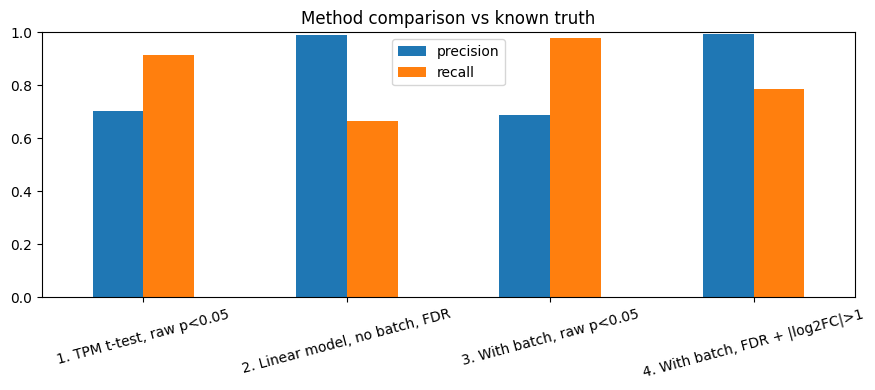

In [ ]:

# Cell 4: Compare methods against the known truth, then show common statistics mistakes

def score(called):
    called = pd.Series(called, index=lcpm.index).reindex(truth.index, fill_value=False)
    tp = int((called & truth).sum()); fp = int((called & ~truth).sum())
    n = int(called.sum())
    return {"genes_called": n, "true_hits": tp, "false_hits": fp,
            "precision": round(tp / max(n, 1), 3), "recall": round(tp / int(truth.sum()), 3)}

results = {}

# Method 1 (WRONG): TPM-like scaling + t-test + raw p < 0.05
scaled = counts_df / counts_df.sum() * 1e6
h = meta.index[meta.condition == "Healthy"]; d = meta.index[meta.condition == "Disease"]
t, p_tpm = stats.ttest_ind(scaled[d].values, scaled[h].values, axis=1)
results["1. TPM t-test, raw p<0.05"] = score(pd.Series(p_tpm < 0.05, index=counts_df.index)[lcpm.index])

# Method 2: log-CPM linear model, NO batch, FDR + fold change
de_nb = de_linear(lcpm, meta, use_batch=False)
de_nb["FDR"] = bh_fdr(de_nb["pval"])
results["2. Linear model, no batch, FDR"] = score((de_nb.FDR < 0.05) & (de_nb.log2FC.abs() > 1))

# Method 3: with batch, but raw p-value
de_b = de_linear(lcpm, meta, use_batch=True)
de_b["FDR"] = bh_fdr(de_b["pval"])
results["3. With batch, raw p<0.05"] = score(de_b.pval < 0.05)

# Method 4 (BEST): with batch, FDR + fold change
results["4. With batch, FDR + |log2FC|>1"] = score((de_b.FDR < 0.05) & (de_b.log2FC.abs() > 1))

res_df = pd.DataFrame(results).T
print(res_df)

# ---- Statistics mistake demo 1: multiple testing ----
# Shuffle labels so there is NO real difference. Any gene called is a false positive.
rng = np.random.default_rng(7)
shuffled = meta.copy()
shuffled["condition"] = rng.permutation(meta.condition.values)
de_null = de_linear(lcpm, shuffled, use_batch=True)
de_null["FDR"] = bh_fdr(de_null["pval"])
print("\nNULL TEST (no real difference exists):")
print("  Genes with raw p < 0.05 :", int((de_null.pval < 0.05).sum()), "<- false positives")
print("  Genes with FDR < 0.05   :", int((de_null.FDR < 0.05).sum()), "<- FDR protects us")

# ---- Statistics mistake demo 2: p-value is not effect size ----
sig = de_b.FDR < 0.05
print("\nEFFECT SIZE CHECK:")
print("  Significant genes (FDR<0.05):", int(sig.sum()))
print("  ...of these, with small effect |log2FC|<0.5:", int((sig & (de_b.log2FC.abs() < 0.5)).sum()))
print("  Lesson: significant does not always mean biologically important. Use FDR + effect size.")

res_df[["precision", "recall"]].plot(kind="bar", figsize=(9, 4), ylim=(0, 1), rot=15)
plt.title("Method comparison vs known truth"); plt.tight_layout(); plt.show()

Cell 5 (Code): Variant filtering, single-cell QC and data leakage

VARIANT FILTERING (Ti/Tv near 2.1 means a clean set):
                             kept  precision  recall  Ti/Tv
No filter                  3000.0      0.833   1.000   1.77
Weak (QUAL>=10)            2954.0      0.846   1.000   1.79
Strong (QUAL>=30, DP>=15)  2464.0      0.971   0.957   1.96

SINGLE-CELL QC:
                                     cells_kept  bad_cells_left  \
No QC                                      1100             200   
Balanced (500-6000 genes, mito<15%)         905               5   
Over-filtered (mito<3%)                     163               2   

                                     good_cells_lost  
No QC                                              0  
Balanced (500-6000 genes, mito<15%)                0  
Over-filtered (mito<3%)                          739  

DATA LEAKAGE TEST (data is pure noise, true accuracy should be about 0.50):
  Feature selection BEFORE split (leaky): 0.93 <- looks great but fake
  Feature selection INSIDE the pipeline : 0.5 <- hon

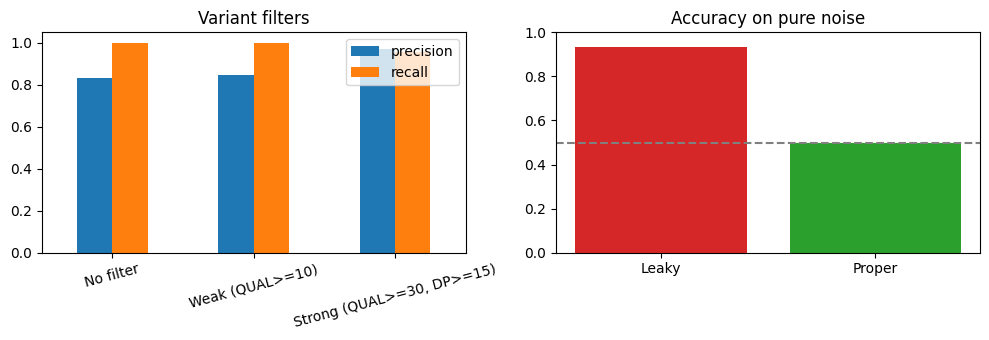

In [ ]:

# Cell 5: Three more interview answers, tested with simulated data
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import cross_val_score, StratifiedKFold

# ================= PART A: Variant calling filters =================
rng = np.random.default_rng(1)
n_true, n_false = 2500, 500
qual = np.r_[rng.normal(60, 15, n_true), rng.normal(25, 12, n_false)]
dp   = np.r_[rng.normal(35, 10, n_true), rng.normal(12, 6, n_false)].clip(1)
is_ti = np.r_[rng.random(n_true) < 2.1/3.1, rng.random(n_false) < 0.5]   # real SNPs: Ti/Tv ~ 2.1
is_true = np.r_[np.ones(n_true, bool), np.zeros(n_false, bool)]

def variant_report(mask):
    kept = int(mask.sum()); tp = int((mask & is_true).sum())
    ti = int((mask & is_ti).sum()); tv = kept - ti
    return {"kept": kept, "precision": round(tp / max(kept, 1), 3),
            "recall": round(tp / n_true, 3), "Ti/Tv": round(ti / max(tv, 1), 2)}

variant_table = pd.DataFrame({
    "No filter":        variant_report(np.ones(len(qual), bool)),
    "Weak (QUAL>=10)":  variant_report(qual >= 10),
    "Strong (QUAL>=30, DP>=15)": variant_report((qual >= 30) & (dp >= 15)),
}).T
print("VARIANT FILTERING (Ti/Tv near 2.1 means a clean set):")
print(variant_table)

# ================= PART B: Single-cell QC =================
rng = np.random.default_rng(2)
n_good, n_dead, n_dbl = 900, 150, 50
genes_det = np.r_[rng.normal(2500, 600, n_good), rng.normal(400, 150, n_dead), rng.normal(7000, 600, n_dbl)]
mito = np.r_[rng.normal(5, 2, n_good).clip(0.5), rng.normal(35, 10, n_dead), rng.normal(6, 2, n_dbl).clip(0.5)]
is_bad = np.r_[np.zeros(n_good, bool), np.ones(n_dead + n_dbl, bool)]

def sc_report(keep):
    return {"cells_kept": int(keep.sum()),
            "bad_cells_left": int((keep & is_bad).sum()),
            "good_cells_lost": int((~keep & ~is_bad).sum())}

sc_table = pd.DataFrame({
    "No QC": sc_report(np.ones(len(mito), bool)),
    "Balanced (500-6000 genes, mito<15%)": sc_report((genes_det > 500) & (genes_det < 6000) & (mito < 15)),
    "Over-filtered (mito<3%)": sc_report((genes_det > 500) & (genes_det < 6000) & (mito < 3)),
}).T
print("\nSINGLE-CELL QC:")
print(sc_table)

# ================= PART C: Data leakage in machine learning =================
rng = np.random.default_rng(3)
X = rng.normal(size=(60, 3000))          # pure noise, 3000 random features
y = np.array([0]*30 + [1]*30)            # random labels: no real signal exists
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)

X_leaky = SelectKBest(f_classif, k=20).fit_transform(X, y)   # WRONG: selects features using ALL data
acc_leaky = cross_val_score(LogisticRegression(max_iter=1000), X_leaky, y, cv=cv).mean()

pipe = make_pipeline(SelectKBest(f_classif, k=20), LogisticRegression(max_iter=1000))  # RIGHT
acc_right = cross_val_score(pipe, X, y, cv=cv).mean()

print("\nDATA LEAKAGE TEST (data is pure noise, true accuracy should be about 0.50):")
print("  Feature selection BEFORE split (leaky):", round(acc_leaky, 2), "<- looks great but fake")
print("  Feature selection INSIDE the pipeline :", round(acc_right, 2), "<- honest")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
variant_table[["precision", "recall"]].plot(kind="bar", ax=ax[0], ylim=(0, 1.05), rot=15)
ax[0].set_title("Variant filters")
ax[1].bar(["Leaky", "Proper"], [acc_leaky, acc_right], color=["tab:red", "tab:green"])
ax[1].axhline(0.5, ls="--", c="grey"); ax[1].set_ylim(0, 1); ax[1].set_title("Accuracy on pure noise")
plt.tight_layout(); plt.show()

Cell 6 (Code): Reproducibility check and final scorecard

In [ ]:

# Cell 6: Same seed + same code = same result. Then a final scorecard.

def run_pipeline(seed):
    c, m, t = make_data(seed)
    cf = filter_genes(c)
    l = log_cpm(cf)
    de = de_linear(l, m, use_batch=True)
    de["FDR"] = bh_fdr(de["pval"])
    return de

def fingerprint(df):
    return hashlib.md5(df.round(8).to_csv().encode()).hexdigest()[:12]

r1 = fingerprint(run_pipeline(42))
r2 = fingerprint(run_pipeline(42))
r3 = fingerprint(run_pipeline(43))

print("Run 1 (seed 42):", r1)
print("Run 2 (seed 42):", r2, "->", "IDENTICAL, reproducible" if r1 == r2 else "DIFFERENT, not reproducible")
print("Run 3 (seed 43):", r3, "->", "different, as expected when the seed changes" if r1 != r3 else "same?")

# ---- Run log (what a real pipeline should save for every run) ----
run_log = {
    "seed": SEED,
    "python": platform.python_version(),
    "numpy": np.__version__, "pandas": pd.__version__,
    "min_count_filter": "10 counts in >=3 samples",
    "normalization": "log2 CPM",
    "model": "~ batch + condition",
    "multiple_testing": "Benjamini-Hochberg FDR",
    "result_fingerprint": r1,
}
print("\nRUN LOG:")
for k, v in run_log.items():
    print(f"  {k}: {v}")

# ---- Final scorecard ----
best = res_df.loc["4. With batch, FDR + |log2FC|>1"]
print("\n" + "=" * 62)
print("FINAL SCORECARD (interview answer -> proof from this lab)")
print("=" * 62)
print(f"1. Pipeline steps     -> QC, filter, CPM, PCA, DE all ran ({counts_f.shape[0]} genes kept)")
print(f"2. Batch effects      -> PC1 vs batch correlation checked; flawed design detected: {design_is_flawed(bad_meta)}")
print(f"3. Method choice      -> best method precision {best['precision']}, recall {best['recall']}")
print( "4. TPM for testing    -> TPM t-test gave more false hits (see Cell 4 table)")
print(f"5. Variant filters    -> strong filter precision {variant_table.loc['Strong (QUAL>=30, DP>=15)','precision']}")
print(f"6. Single-cell QC     -> balanced QC kept good cells; over-filtering lost {sc_table.loc['Over-filtered (mito<3%)','good_cells_lost']}")
print(f"7. Stats mistakes     -> raw p gave {int((de_null.pval < 0.05).sum())} false genes on null data; FDR gave {int((de_null.FDR < 0.05).sum())}")
print(f"8. Data leakage       -> leaky {round(acc_leaky,2)} vs proper {round(acc_right,2)} on pure noise")
print(f"9. Reproducibility    -> same seed gives same fingerprint: {r1 == r2}")
print("\nNote: a simple linear model on log-CPM is used so the lab runs fast. On real data use")
print("DESeq2 / edgeR / limma-voom (or PyDESeq2) on raw counts. The design logic is the same.")

Run 1 (seed 42): 4fec81e24597
Run 2 (seed 42): 4fec81e24597 -> IDENTICAL, reproducible
Run 3 (seed 43): 5b40e04f4c6e -> different, as expected when the seed changes

RUN LOG:
  seed: 42
  python: 3.13.16
  numpy: 2.1.3
  pandas: 2.2.3
  min_count_filter: 10 counts in >=3 samples
  normalization: log2 CPM
  model: ~ batch + condition
  multiple_testing: Benjamini-Hochberg FDR
  result_fingerprint: 4fec81e24597

FINAL SCORECARD (interview answer -> proof from this lab)
1. Pipeline steps     -> QC, filter, CPM, PCA, DE all ran (1491 genes kept)
2. Batch effects      -> PC1 vs batch correlation checked; flawed design detected: True
3. Method choice      -> best method precision 0.992, recall 0.787
4. TPM for testing    -> TPM t-test gave more false hits (see Cell 4 table)
5. Variant filters    -> strong filter precision 0.971
6. Single-cell QC     -> balanced QC kept good cells; over-filtering lost 739
7. Stats mistakes     -> raw p gave 79 false genes on null data; FDR gave 0
8. Data leak